In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [16]:
DATA_PATH = Path("../raw/ibtracs.ALL.list.v04r01.csv")

df = pd.read_csv(DATA_PATH, skiprows=[1], low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (729694, 174)


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,...,BOM_GUST_PER,REUNION_GUST,REUNION_GUST_PER,USA_SEAHGT,USA_SEARAD_NE,USA_SEARAD_SE,USA_SEARAD_SW,USA_SEARAD_NW,STORM_SPEED,STORM_DIR
0,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 03:00:00,NR,10.9,80.3,...,,,,,,,,,9,265
1,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 06:00:00,NR,10.9,79.8,...,,,,,,,,,9,265
2,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 09:00:00,NR,10.8,79.4,...,,,,,,,,,9,265
3,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 12:00:00,NR,10.8,78.9,...,,,,,,,,,9,265
4,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 15:00:00,NR,10.8,78.4,...,,,,,,,,,9,270


In [17]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.info()

Number of rows: 729694
Number of columns: 174

Column names:
['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT', 'KMA_R30_DIR', 'KMA_R

In [18]:
columns = [
    "SID", "NAME", "ISO_TIME", "LAT", "LON",
    "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"
]

available_columns = [col for col in columns if col in df.columns]

cyclone_df = df[available_columns].copy()

cyclone_df.head()

,SID,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES,USA_WIND,USA_SSHS
0,1842298N11080,UNNAMED,1842-10-25 03:00:00,10.9,80.3,,,,-5
1,1842298N11080,UNNAMED,1842-10-25 06:00:00,10.9,79.8,,,,-5
2,1842298N11080,UNNAMED,1842-10-25 09:00:00,10.8,79.4,,,,-5
3,1842298N11080,UNNAMED,1842-10-25 12:00:00,10.8,78.9,,,,-5
4,1842298N11080,UNNAMED,1842-10-25 15:00:00,10.8,78.4,,,,-5


In [19]:
for col in ["LAT", "LON", "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"]:
    if col in cyclone_df.columns:
        cyclone_df[col] = pd.to_numeric(
            cyclone_df[col], errors="coerce"
        )

cyclone_df["ISO_TIME"] = pd.to_datetime(
    cyclone_df["ISO_TIME"], errors="coerce"
)

print(cyclone_df.dtypes)

SID                    str
NAME                   str
ISO_TIME    datetime64[us]
LAT                float64
LON                float64
WMO_WIND           float64
WMO_PRES           float64
USA_WIND           float64
USA_SSHS             int64
dtype: object


Missing values per column:
SID              0
NAME             0
ISO_TIME         0
LAT              0
LON              0
WMO_WIND    559378
WMO_PRES    555701
USA_WIND    324482
USA_SSHS         0
dtype: int64


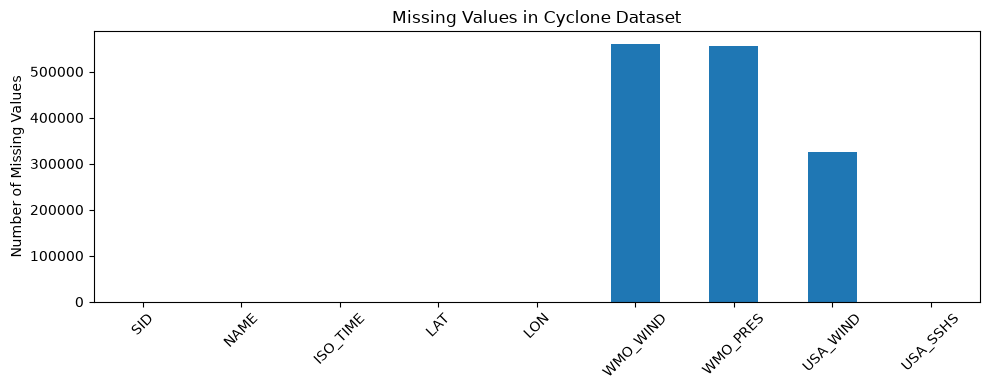

In [20]:
missing = cyclone_df.isnull().sum()

print("Missing values per column:")
print(missing)

missing.plot(kind="bar", figsize=(10, 4))
plt.title("Missing Values in Cyclone Dataset")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
north_indian = df[df["BASIN"] == "NI"].copy()

print("North Indian Ocean records:", len(north_indian))
print("Unique storms:", north_indian["SID"].nunique())

north_indian.head()

North Indian Ocean records: 57853
Unique storms: 1859


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,...,BOM_GUST_PER,REUNION_GUST,REUNION_GUST_PER,USA_SEAHGT,USA_SEARAD_NE,USA_SEARAD_SE,USA_SEARAD_SW,USA_SEARAD_NW,STORM_SPEED,STORM_DIR
0,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 03:00:00,NR,10.9,80.3,...,,,,,,,,,9,265
1,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 06:00:00,NR,10.9,79.8,...,,,,,,,,,9,265
2,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 09:00:00,NR,10.8,79.4,...,,,,,,,,,9,265
3,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 12:00:00,NR,10.8,78.9,...,,,,,,,,,9,265
4,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 15:00:00,NR,10.8,78.4,...,,,,,,,,,9,270


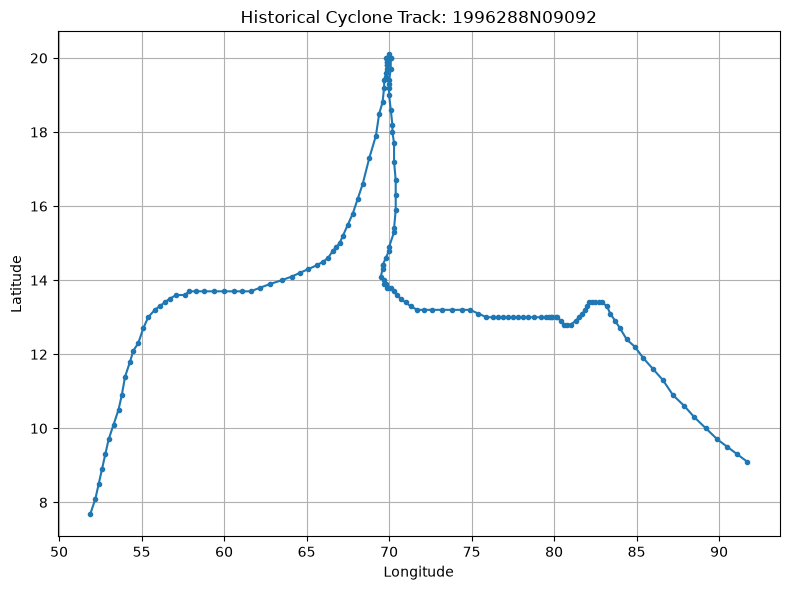

In [22]:
north_indian["LAT"] = pd.to_numeric(
    north_indian["LAT"], errors="coerce"
)
north_indian["LON"] = pd.to_numeric(
    north_indian["LON"], errors="coerce"
)

north_indian["ISO_TIME"] = pd.to_datetime(
    north_indian["ISO_TIME"], errors="coerce"
)

storm_counts = north_indian.groupby("SID")["LAT"].count()
storm_counts = storm_counts[storm_counts > 1]

if not storm_counts.empty:
    storm_id = storm_counts.idxmax()
    storm = north_indian[north_indian["SID"] == storm_id].copy()
    storm = storm.sort_values("ISO_TIME")
    storm = storm.dropna(subset=["LAT", "LON"])

    plt.figure(figsize=(8, 6))
    plt.plot(storm["LON"], storm["LAT"], marker="o", markersize=3)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"Historical Cyclone Track: {storm_id}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable storm track found.")

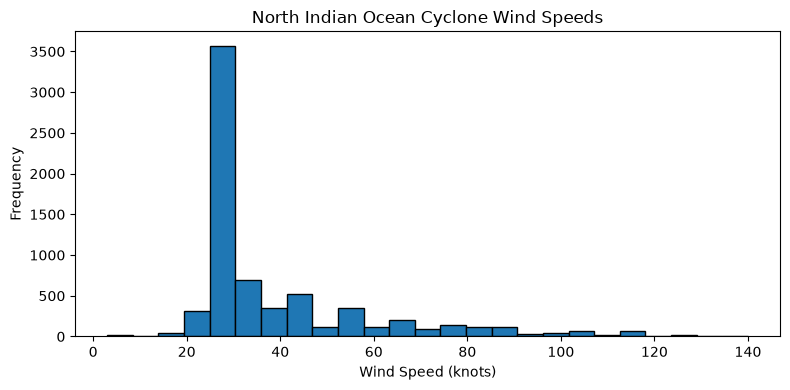

In [23]:
wind_col = "WMO_WIND"

if wind_col in north_indian.columns:
    wind = pd.to_numeric(north_indian[wind_col], errors="coerce")
    wind = wind.dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(wind, bins=25, edgecolor="black")
    plt.xlabel("Wind Speed (knots)")
    plt.ylabel("Frequency")
    plt.title("North Indian Ocean Cyclone Wind Speeds")
    plt.tight_layout()
    plt.show()

In [24]:
OUTPUT_PATH = Path("../processed/north_indian_cyclones.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

north_indian.to_csv(OUTPUT_PATH, index=False)

In [25]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.info()

Number of rows: 729694
Number of columns: 174

Column names:
['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT', 'KMA_R30_DIR', 'KMA_R

In [26]:
columns = [
    "SID", "NAME", "ISO_TIME", "LAT", "LON",
    "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"
]

available_columns = [col for col in columns if col in df.columns]

cyclone_df = df[available_columns].copy()

cyclone_df.head()

,SID,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES,USA_WIND,USA_SSHS
0,1842298N11080,UNNAMED,1842-10-25 03:00:00,10.9,80.3,,,,-5
1,1842298N11080,UNNAMED,1842-10-25 06:00:00,10.9,79.8,,,,-5
2,1842298N11080,UNNAMED,1842-10-25 09:00:00,10.8,79.4,,,,-5
3,1842298N11080,UNNAMED,1842-10-25 12:00:00,10.8,78.9,,,,-5
4,1842298N11080,UNNAMED,1842-10-25 15:00:00,10.8,78.4,,,,-5


In [27]:
numeric_columns = [
    "LAT", "LON", "WMO_WIND",
    "WMO_PRES", "USA_WIND", "USA_SSHS"
]

for col in numeric_columns:
    if col in cyclone_df.columns:
        cyclone_df[col] = pd.to_numeric(
            cyclone_df[col], errors="coerce"
        )

cyclone_df["ISO_TIME"] = pd.to_datetime(
    cyclone_df["ISO_TIME"], errors="coerce"
)

print(cyclone_df.dtypes)

SID                    str
NAME                   str
ISO_TIME    datetime64[us]
LAT                float64
LON                float64
WMO_WIND           float64
WMO_PRES           float64
USA_WIND           float64
USA_SSHS             int64
dtype: object


In [ ]:
missing_values = cyclone_df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

missing_percentage = (
    cyclone_df.isnull().sum() / len(cyclone_df) * 100
).round(2)

print("\nMissing percentage:")
print(missing_percentage)

In [ ]:
missing_values[missing_values > 0].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.title("Missing Values in Cyclone Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
north_indian = df[df["BASIN"].astype(str).str.strip() == "NI"].copy()

print("North Indian Ocean records:", len(north_indian))
print("Unique storms:", north_indian["SID"].nunique())

north_indian.head()

In [ ]:
north_indian["LAT"] = pd.to_numeric(
    north_indian["LAT"], errors="coerce"
)

north_indian["LON"] = pd.to_numeric(
    north_indian["LON"], errors="coerce"
)

north_indian["ISO_TIME"] = pd.to_datetime(
    north_indian["ISO_TIME"], errors="coerce"
)

storm_counts = (
    north_indian.dropna(subset=["LAT", "LON"])
    .groupby("SID")
    .size()
)

storm_counts = storm_counts[storm_counts > 1]

if not storm_counts.empty:
    storm_id = storm_counts.idxmax()

    storm = north_indian[
        north_indian["SID"] == storm_id
    ].sort_values("ISO_TIME")

    storm = storm.dropna(subset=["LAT", "LON"])

    plt.figure(figsize=(8, 6))
    plt.plot(storm["LON"], storm["LAT"], marker="o", markersize=3)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"Historical Cyclone Track: {storm_id}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable cyclone track found.")

In [4]:
import pandas as pd

df = pd.read_csv("../raw/ibtracs.ALL.list.v04r01.csv", low_memory=False)

# Convert the observation time to datetime
# Parse timestamps consistently
df["ISO_TIME"] = pd.to_datetime(
    df["ISO_TIME"], format="mixed", errors="coerce"
)

# Filter for the North Indian Ocean
nio = df[df["BASIN"] == "NI"].copy()

# Select observations from 24–25 October 2024
check = nio[
    (nio["ISO_TIME"] >= "2024-10-24") &
    (nio["ISO_TIME"] < "2024-10-26")
]

check[
    ["SID", "NAME", "ISO_TIME", "LAT", "LON",
     "WMO_WIND", "USA_WIND", "NEWDELHI_WIND"]
].head(20)

,SID,NAME,ISO_TIME,LAT,LON,WMO_WIND,USA_WIND,NEWDELHI_WIND
716808,2024295N15092,DANA,2024-10-24 00:00:00,18.7,88.2,55,60,55
716809,2024295N15092,DANA,2024-10-24 03:00:00,19.0,88.0,55,63,55
716810,2024295N15092,DANA,2024-10-24 06:00:00,19.3,87.8,55,65,55
716811,2024295N15092,DANA,2024-10-24 09:00:00,19.5,87.6,60,65,60
716812,2024295N15092,DANA,2024-10-24 12:00:00,19.8,87.5,60,65,60
716813,2024295N15092,DANA,2024-10-24 15:00:00,20.1,87.3,60,63,60
716814,2024295N15092,DANA,2024-10-24 18:00:00,20.5,87.1,55,60,55
716815,2024295N15092,DANA,2024-10-24 21:00:00,20.7,87.0,55,58,55
716816,2024295N15092,DANA,2024-10-25 00:00:00,20.9,86.9,50,55,50
716817,2024295N15092,DANA,2024-10-25 03:00:00,21.1,86.8,45,53,45


In [5]:
print("Number of observations:", len(check))

print("\nCyclone names found:")
print(check["NAME"].value_counts())

print("\nUnique cyclone tracks:")
print(
    check[["SID", "NAME"]]
    .drop_duplicates()
    .to_string(index=False)
)

Number of observations: 16

Cyclone names found:
NAME
DANA    16
Name: count, dtype: int64

Unique cyclone tracks:
          SID NAME
2024295N15092 DANA


In [ ]:
dana = check[check["NAME"] == "DANA"].copy()

print(
    dana[
        ["ISO_TIME", "LAT", "LON",
         "NEWDELHI_WIND", "WMO_WIND"]
    ]
    .sort_values("ISO_TIME")
    .to_string(index=False)
)

In [6]:
dana = check[check["NAME"] == "DANA"].copy()

print(
    dana[
        ["ISO_TIME", "LAT", "LON",
         "NEWDELHI_WIND", "WMO_WIND"]
    ]
    .sort_values("ISO_TIME")
    .to_string(index=False)
)

           ISO_TIME  LAT  LON NEWDELHI_WIND WMO_WIND
2024-10-24 00:00:00 18.7 88.2            55       55
2024-10-24 03:00:00 19.0 88.0            55       55
2024-10-24 06:00:00 19.3 87.8            55       55
2024-10-24 09:00:00 19.5 87.6            60       60
2024-10-24 12:00:00 19.8 87.5            60       60
2024-10-24 15:00:00 20.1 87.3            60       60
2024-10-24 18:00:00 20.5 87.1            55       55
2024-10-24 21:00:00 20.7 87.0            55       55
2024-10-25 00:00:00 20.9 86.9            50       50
2024-10-25 03:00:00 21.1 86.8            45       45
2024-10-25 06:00:00 21.2 86.7            35       35
2024-10-25 09:00:00 21.3 86.6            30       30
2024-10-25 12:00:00 21.3 86.5            30       30
2024-10-25 15:00:00 21.3 86.4            28         
2024-10-25 18:00:00 21.3 86.4            25       25
2024-10-25 21:00:00 21.2 86.5                       


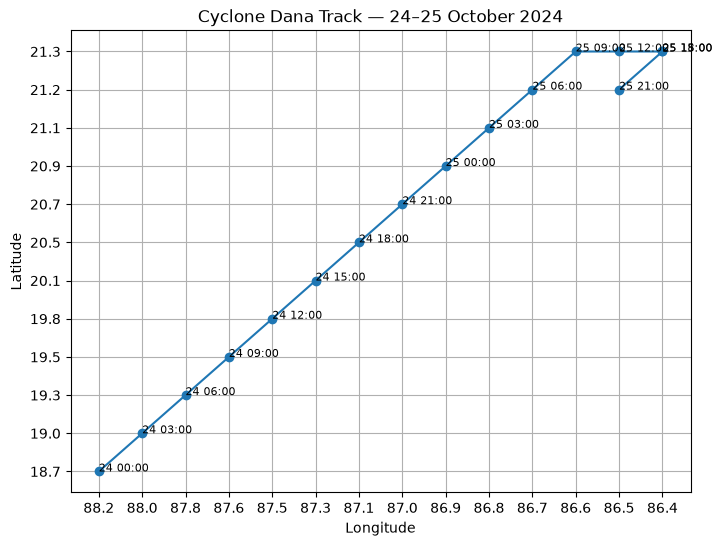

In [8]:
import matplotlib.pyplot as plt

dana = check[check["NAME"] == "DANA"].copy()
dana = dana.sort_values("ISO_TIME")

plt.figure(figsize=(8, 6))

plt.plot(dana["LON"], dana["LAT"], marker="o")

for _, row in dana.iterrows():
    plt.annotate(
        row["ISO_TIME"].strftime("%d %H:%M"),
        (row["LON"], row["LAT"]),
        fontsize=8
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Cyclone Dana Track — 24–25 October 2024")
plt.grid(True)
plt.show()

In [9]:
# Satellite observation time: 25 Oct 2024, 04:13 IST
# Convert to UTC for comparison with IBTrACS
satellite_time = pd.Timestamp("2024-10-25 04:13:00", tz="Asia/Kolkata")
satellite_time_utc = satellite_time.tz_convert("UTC").tz_localize(None)

print("Satellite time (UTC):", satellite_time_utc)

nearest = dana.iloc[
    (dana["ISO_TIME"] - satellite_time_utc).abs().argsort()[:3]
]

print("\nNearest recorded Dana observations:")
print(
    nearest[
        ["ISO_TIME", "LAT", "LON", "NEWDELHI_WIND", "WMO_WIND"]
    ].to_string(index=False)
)

Satellite time (UTC): 2024-10-24 22:43:00

Nearest recorded Dana observations:
           ISO_TIME  LAT  LON NEWDELHI_WIND WMO_WIND
2024-10-25 00:00:00 20.9 86.9            50       50
2024-10-24 21:00:00 20.7 87.0            55       55
2024-10-25 03:00:00 21.1 86.8            45       45


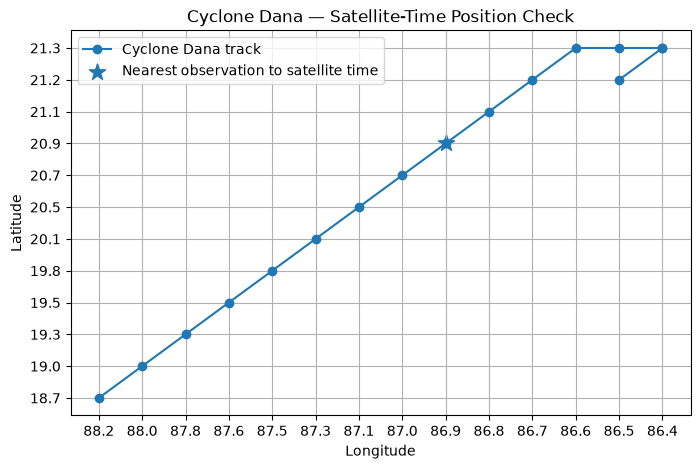

Nearest observation time: 2024-10-25 00:00:00
Latitude: 20.9
Longitude: 86.9


In [10]:
import matplotlib.pyplot as plt

nearest_row = nearest.iloc[0]

plt.figure(figsize=(8, 5))
plt.plot(dana["LON"], dana["LAT"], marker="o", label="Cyclone Dana track")
plt.scatter(
    nearest_row["LON"],
    nearest_row["LAT"],
    s=150,
    marker="*",
    label="Nearest observation to satellite time"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Cyclone Dana — Satellite-Time Position Check")
plt.grid(True)
plt.legend()
plt.show()

print("Nearest observation time:", nearest_row["ISO_TIME"])
print("Latitude:", nearest_row["LAT"])
print("Longitude:", nearest_row["LON"])

### Historical Track Comparison

The satellite observation dated 25 October 2024 was compared with Cyclone Dana's historical track using IBTrACS data.

- The storm's recorded positions were plotted using latitude and longitude.
- The satellite timestamp was converted from Indian Standard Time (IST) to Coordinated Universal Time (UTC) for comparison.
- The nearest recorded storm observation was identified.

**Conclusion:** This comparison establishes a method for checking satellite observations against historical cyclone records. Further verification of the image's geographic coverage and cloud-system location is required before confirming a match.

In [11]:
from PIL import Image

image_path = "../raw/satellite_samples/insat_cyclone_20241025.jpg"

img = Image.open(image_path)

print("Image format:", img.format)
print("Image dimensions:", img.size)
print("Image mode:", img.mode)
print("Image metadata:")
print(img.info)

Image format: JPEG
Image dimensions: (2040, 2243)
Image mode: RGB
Image metadata:
{'jfif': 257, 'jfif_version': (1, 1), 'jfif_unit': 0, 'jfif_density': (1, 1)}
